# Waiting for the next matatu

**NganyaFlow · October 2026**

At Kencom, does knowing the gap between the last two vehicles help us predict the next arrival? We tested a quantile regression forest against two simpler estimates. All arrival times in this experiment were simulated. The three boarding points are real.

In [1]:
import json
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

from nganyaflow.datasets import validate_bundle
from nganyaflow.ml import train
from nganyaflow.schemas import Catalog
from nganyaflow.synthetic import CATALOG

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "server/data/examples/nairobi-cbd-synthetic-v1.json").is_file())
bundle = json.loads((root / "server/data/examples/nairobi-cbd-synthetic-v1.json").read_text(encoding="utf-8"))

## The arrival records

Each session covers one stage, route and direction. We checked that each arrival fell inside its session and that observation IDs and arrival times were unique within the relevant records. All 1,049 arrivals passed. For training, we used only waits with a later arrival in the same session.

In [2]:
metadata, sessions, _, events = validate_bundle(bundle, Catalog.model_validate(CATALOG))
assert metadata["data_kind"] == "synthetic"
arrivals = [
    {**sessions[str(event.session_id)].model_dump(mode="json"), **event.model_dump(mode="json")}
    for event in events if event.event_type == "arrival"
]
by_stage = pd.DataFrame(arrivals).groupby("stage_id").agg(
    Sessions=("session_id", "nunique"), Arrivals=("observed_at", "size")
)
by_stage.index = by_stage.index.str.title()
by_stage.rename_axis("Stage")

,Sessions,Arrivals
Stage,,
Kencom,28,453
Odeon,28,341
Railways,28,255


## What the forest learns

Suppose vehicles arrive at 07:00, 07:06 and 07:14. At 07:09 the previous gap was six minutes and three minutes have passed since the last arrival. The five minutes until 07:14 supply the training label.

The forest uses the stage, route, direction, local time, weekday, previous gap and elapsed time. Its 100 trees estimate a median wait and a range from the 10th to the 90th percentile. We trained on 5–15 October and held out 16–18 October so neighbouring queries from one session stayed together.

In [3]:
with TemporaryDirectory() as scratch:
    model_file = Path(scratch) / "forest.joblib"
    run = train(arrivals, model_file, test_days=3, diagnostics=False)
    predictions = pd.read_csv(model_file.with_suffix(".predictions.csv"))

pd.DataFrame(
    {"Dates": [len(run["train_days"]), len(run["test_days"])],
     "Sessions": [run["train_sessions"], run["test_sessions"]],
     "Wait queries": [run["train_samples"], run["test_samples"]]},
    index=["Training", "Held out"],
)

,Dates,Sessions,Wait queries
Training,11,66,4684
Held out,3,18,1259


## How far off were the predictions?

The last-gap rule assumes the next gap will equal the previous one and subtracts the time already elapsed. It was the closer of our two baselines. Using the forest reduced mean absolute error by about five seconds per query on the held-out dates.

In [4]:
actual = predictions["actual_wait_minutes"]
methods = {
    "Quantile forest (median)": "median_minutes",
    "Last-gap rule": "last_headway_minutes",
    "Historical median": "historical_median_minutes",
}
scores = pd.DataFrame.from_dict({
    name: {"MAE (min)": mean_absolute_error(actual, predictions[col]),
           "RMSE (min)": root_mean_squared_error(actual, predictions[col]),
           "R²": r2_score(actual, predictions[col])}
    for name, col in methods.items()
}, orient="index")
scores.style.format("{:.3f}")

,MAE (min),RMSE (min),R²
Quantile forest (median),0.939,1.170,0.844
Last-gap rule,1.018,1.259,0.820
Historical median,2.211,2.828,0.091


## How often did the range contain the next arrival?

The band below covers the middle 80% of waits predicted by the forest. Each dot is the wait until the next simulated vehicle at that query time. The first twenty queries from the first held-out Kencom session include misses as well as hits.

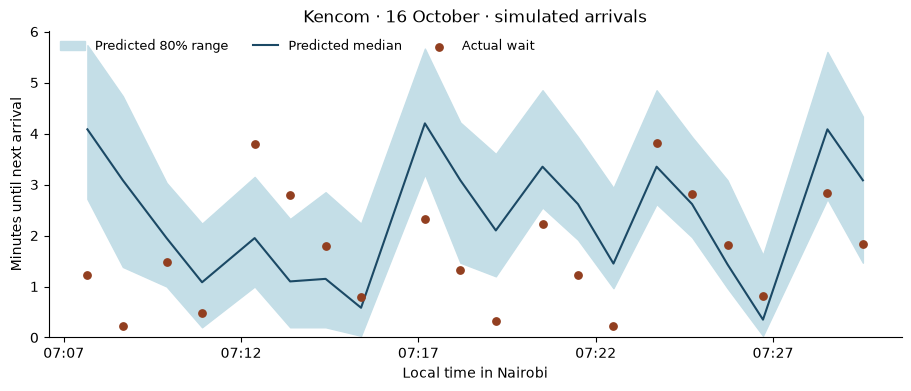

In [5]:
kencom = predictions.query("stage_id == 'kencom'").sort_values("query_at")
first_session = kencom.iloc[0]["session_id"]
sample = kencom.loc[kencom["session_id"] == first_session].head(20)
time = pd.to_datetime(sample["query_at"], utc=True).dt.tz_convert("Africa/Nairobi")

fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
ax.fill_between(time, sample["lower_minutes"], sample["upper_minutes"],
                color="#C4DEE7", label="Predicted 80% range")
ax.plot(time, sample["median_minutes"], color="#1B4965", label="Predicted median")
ax.scatter(time, sample["actual_wait_minutes"], s=28, color="#923F20", label="Actual wait", zorder=3)
ax.set(title="Kencom · 16 October · simulated arrivals", ylabel="Minutes until next arrival",
       xlabel="Local time in Nairobi", ylim=(0, None))
ax.xaxis.set_major_locator(mdates.MinuteLocator(interval=5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=time.dt.tz))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.01), ncol=3, frameon=False, fontsize=9)
ax.margins(y=.22)
plt.show()

In [5]:
inside = actual.between(predictions["lower_minutes"], predictions["upper_minutes"])
width = predictions["upper_minutes"] - predictions["lower_minutes"]
print(f"Across all {len(actual):,} held-out queries, {inside.sum():,} fell inside the range "
      f"({inside.mean():.2%}).")
print(f"The range averaged {width.mean():.2f} minutes wide.")

Across all 1,259 held-out queries, 1,008 fell inside the range (80.06%).
The range averaged 3.10 minutes wide.


Kencom’s range covered about 77% of its waits. At Railways it covered about 86%. The overall figure hides that difference. To find out how well the range works for Nairobi commuters, we need continuous arrival logs collected at the stages themselves.